# Неделя 22. Microsoft Copilot Studio: основы

**Практикум · Tech Orda · Gizatov A. S.**

Два занятия по 90 минут: 72 минуты теории и 108 минут практики за неделю.
Выполняйте ячейки последовательно через **Restart Kernel → Run All**.
Все обязательные вычисления работают на CPU без сети и API-ключей.

**Результат:** описать агента, knowledge и topic; проверить маршрутизацию и заполнение переменных локально, затем перенести сценарий в Copilot Studio.

**Это simulator:** Python ниже не создает и не тестирует Microsoft Copilot Studio. Настоящие действия в сервисе описаны в COPILOT_STUDIO_LAB.md; результат live-run пока not_run.


In [1]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Работает из корня репозитория, папки недели и подпапок practice/homework.
_here = Path.cwd().resolve()
ROOT = next(p for p in [_here, *_here.parents] if (p / "course_plan.json").exists())
WEEK = ROOT / "week_22_copilot_basics"
DATA = WEEK / "datasets"
SEED = 122
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "font.size": 10})
print("Локальный CPU-режим; данные:", DATA.name)


Локальный CPU-режим; данные: datasets


## 1. Задача агента

Course Helper помогает с учебной домашней работой и готовит черновик запроса на консультацию. Knowledge отвечает на вопросы, topic задает последовательность действий, variable хранит выбранное значение. Генеративная и classic orchestration выбирают topics по-разному.


,case_id,utterance,expected_topic
0,C01,Хочу консультацию,consultation
1,C02,Записаться на консультацию,consultation
2,C03,Когда консультация?,consultation
3,C04,Мне нужна консультация по Python,consultation
4,C05,Как сдать домашнюю работу?,homework
5,C06,Куда отправить домашнюю?,homework
6,C07,Срок домашней работы,homework
7,C08,Здравствуйте,fallback
8,C09,Какой сегодня курс валют?,fallback
9,C10,Хочу записаться к врачу,fallback


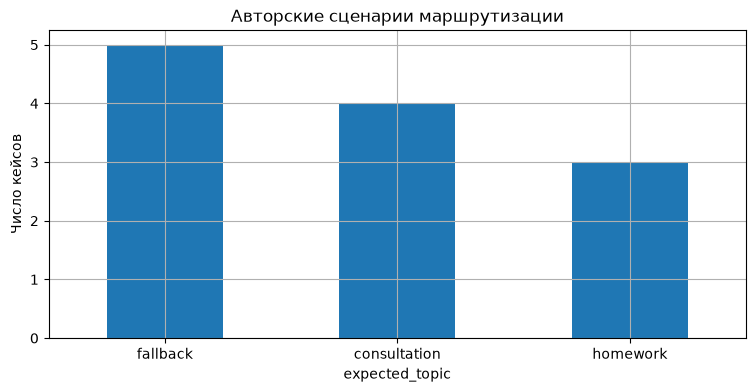

In [2]:
cases = pd.read_csv(DATA / 'topic_cases.csv')
knowledge = (DATA / 'course_knowledge.txt').read_text(encoding='utf-8')
display(cases)
cases.expected_topic.value_counts().plot.bar(rot=0, title='Авторские сценарии маршрутизации')
plt.ylabel('Число кейсов'); plt.show()
assert cases.case_id.is_unique


## 2. Контракт агента

Описание должно называть аудиторию, задачи, ограничения и источник ответа. Само обещание в instructions не обеспечивает контроль доступа; permissions реализуются отдельно. В этом сценарии не выполняются записи календаря.


In [3]:
agent_spec = {
    'name': 'Course Helper Lab',
    'audience': 'Студенты учебной группы',
    'tasks': ['Вопросы о домашней работе', 'Черновик запроса консультации'],
    'knowledge': 'course_knowledge.txt',
    'instructions': 'Отвечай по базе знаний. Уточняй недостающую тему. Не выдумывай расписание. '
                    'Не запрашивай пароли. Сообщай, когда действие только подготовлено.',
}
display(agent_spec)


{'name': 'Course Helper Lab',
 'audience': 'Студенты учебной группы',
 'tasks': ['Вопросы о домашней работе', 'Черновик запроса консультации'],
 'knowledge': 'course_knowledge.txt',
 'instructions': 'Отвечай по базе знаний. Уточняй недостающую тему. Не выдумывай расписание. Не запрашивай пароли. Сообщай, когда действие только подготовлено.'}

## 3. Прозрачная учебная маршрутизация

Используем keyword rules, чтобы увидеть ошибки маршрутизации. Это не NLU Copilot Studio: сервис может обобщать фразы, а генеративная orchestration использует описания topics. Метрики ниже относятся только к нашей функции.


In [4]:
def route_topic(text):
    low = text.lower()
    if 'консультац' in low:
        return 'consultation'
    if 'домашн' in low:
        return 'homework'
    return 'fallback'
cases['predicted'] = cases.utterance.map(route_topic)
display(pd.crosstab(cases.expected_topic, cases.predicted))
print('Точность учебных правил:', cases.predicted.eq(cases.expected_topic).mean())
assert route_topic('курс валют') == 'fallback'


predicted,consultation,fallback,homework
expected_topic,,,
consultation,4,0,0
fallback,0,5,0
homework,0,0,3


Точность учебных правил: 1.0


## 4. Диалог как конечный автомат

Topic консультации: start → ask_topic → ask_day → confirm → complete. Ветвление зависит от переменной, а не от позиции слова в предложении. Неизвестное значение сохраняет текущий шаг и вызывает уточнение.


In [5]:
from dataclasses import dataclass
@dataclass
class Consultation:
    state: str = 'ask_topic'
    topic: str | None = None
    day: str | None = None
    confirmed: bool = False

    def respond(self, text):
        text = text.strip()
        if self.state == 'ask_topic':
            if text not in {'Python', 'ML', 'Project'}:
                return 'Выберите Python, ML или Project.'
            self.topic, self.state = text, 'ask_day'
            return 'Выберите Tuesday или Thursday.'
        if self.state == 'ask_day':
            if text not in {'Tuesday', 'Thursday'}:
                return 'Допустимы Tuesday или Thursday.'
            self.day, self.state = text, 'confirm'
            return f'Черновик: {self.topic}, {self.day}. Подтвердить? yes/no'
        if self.state == 'confirm':
            if text.lower() not in {'yes', 'no'}:
                return 'Ответьте yes или no.'
            self.confirmed = text.lower() == 'yes'
            self.state = 'complete'
            return 'Черновик подготовлен; календарь не изменен.' if self.confirmed else 'Отменено.'
        return 'Диалог завершен. Начните новую сессию.'
dialog = Consultation()
print(dialog.respond('Python')); print(dialog.respond('Tuesday')); print(dialog.respond('yes'))
assert dialog.confirmed and dialog.state == 'complete'


Выберите Tuesday или Thursday.
Черновик: Python, Tuesday. Подтвердить? yes/no
Черновик подготовлен; календарь не изменен.


## 5. Неверное значение не повреждает state

Проверим backstop: пользователь ввел «завтра», затем допустимый день. До подтверждения операция остается черновиком. В студии аналог — Question node и Condition node.


In [6]:
test_dialog = Consultation()
assert test_dialog.respond('Unknown') == 'Выберите Python, ML или Project.'
assert test_dialog.state == 'ask_topic' and test_dialog.topic is None
test_dialog.respond('ML')
test_dialog.respond('tomorrow')
assert test_dialog.state == 'ask_day' and test_dialog.day is None
test_dialog.respond('Thursday')
assert not test_dialog.confirmed
test_dialog.respond('no')
assert test_dialog.state == 'complete' and not test_dialog.confirmed
print('Недопустимые значения и отмена обработаны.')


Недопустимые значения и отмена обработаны.


## 6. Переменные сессии

Topic-local значения принадлежат одному диалогу. Глобальная переменная удобна для повторного использования, но требует понимания жизненного цикла. В Python имитируем отдельным объектом для каждой сессии.


In [7]:
sessions = {'S1': Consultation(), 'S2': Consultation()}
sessions['S1'].respond('Python')
sessions['S2'].respond('Project')
assert sessions['S1'].topic != sessions['S2'].topic
display(pd.DataFrame([{'session': key, **vars(value)} for key, value in sessions.items()]))


,session,state,topic,day,confirmed
0,S1,ask_day,Python,None,False
1,S2,ask_day,Project,None,False


## 7. Knowledge-grounded ответ без свободной генерации

В локальном эквиваленте на вопрос о домашней работе возвращаем проверенную строку. В Copilot Studio добавим этот TXT как knowledge и проверим ссылку на источник и отсутствие обещаний вне документа.


In [8]:
def answer_known_topic(text):
    topic = route_topic(text)
    if topic == 'homework':
        return next(line for line in knowledge.splitlines() if line.startswith('Домашняя работа'))
    if topic == 'consultation':
        return 'Выберите Python, ML или Project.'
    return 'В учебной базе нет подходящего ответа.'
answer = answer_known_topic('Как сдать домашнюю?')
assert answer in knowledge
assert answer_known_topic('Курс валют?') == 'В учебной базе нет подходящего ответа.'
print(answer)


Домашняя работа сдается в приватный репозиторий до воскресенья 23:59.


## 8. Матрица acceptance tests

Набор должен проверять happy path, отсутствующие slots, отмену, fallback и изоляцию. Отдельная колонка указывает среду: все результаты здесь offline_simulator. Live результат надо наблюдать в Test your agent.


In [9]:
acceptance = pd.DataFrame([
    ('маршрутизация', 'passed'), ('валидные slots', 'passed'), ('невалидный день', 'passed'),
    ('отмена', 'passed'), ('изоляция сессий', 'passed'),
], columns=['check', 'status']).assign(environment='offline_simulator')
display(acceptance)
live_record = {'environment': 'copilot_studio', 'status': 'not_run', 'evidence': None}
display(live_record)


,check,status,environment
0,маршрутизация,passed,offline_simulator
1,валидные slots,passed,offline_simulator
2,невалидный день,passed,offline_simulator
3,отмена,passed,offline_simulator
4,изоляция сессий,passed,offline_simulator


{'environment': 'copilot_studio', 'status': 'not_run', 'evidence': None}

## 9. Сопоставление с UI

При переносе сохраняем смысл сценария. В разных версиях Microsoft названия разделов могут меняться. Наличие черновика YAML не означает, что сервис его импортировал; проверяйте Save и видимый canvas.


In [10]:
mapping = pd.DataFrame([
    ('agent_spec', 'Overview / Instructions'), ('knowledge TXT', 'Knowledge / Add knowledge'),
    ('route_topic', 'Topic trigger / description'), ('state ask_topic', 'Question node'),
    ('allowed choices', 'Entity / Condition'), ('confirmed', 'Boolean variable'),
], columns=['Python analogue', 'Copilot Studio element'])
display(mapping)


,Python analogue,Copilot Studio element
0,agent_spec,Overview / Instructions
1,knowledge TXT,Knowledge / Add knowledge
2,route_topic,Topic trigger / description
3,state ask_topic,Question node
4,allowed choices,Entity / Condition
5,confirmed,Boolean variable


## 10. Подготовка к настоящей лабораторной

Соседний Markdown содержит пошаговое создание агента. Файл topic_consultation.yaml — учебная заготовка простого topic для code editor стандартного harness; интерфейс canvas остается главным способом проверки.


In [11]:
assert (WEEK / 'practice' / 'COPILOT_STUDIO_LAB.md').exists()
print('Live Copilot Studio validation: not_run')


Live Copilot Studio validation: not_run


## Источники и следующий шаг

- [Microsoft: create an agent](https://learn.microsoft.com/en-us/microsoft-copilot-studio/fundamentals-get-started)
- [Microsoft: topics and variables](https://learn.microsoft.com/en-us/microsoft-copilot-studio/authoring-create-edit-topics)
- [Microsoft: knowledge](https://learn.microsoft.com/en-us/microsoft-copilot-studio/knowledge-copilot-studio)

Откройте Markdown-задание в папке `../homework/` своей недели. Перед сдачей перезапустите ядро и убедитесь, что выводы соответствуют фактическим результатам.
